In [ ]:
from google.colab import drive
#drive.mount('/content/drive')

import sys, os
from pathlib import Path
try:
  import google.colab
  USING_COLAB = True
except:
  USING_COLAB = False

if USING_COLAB:

  os.chdir("/content")
  os.system("git clone https://github.com/src47/multibax-sklearn.git")
  os.chdir("multibax-sklearn")
  sys.path.extend(["/content/multibax-sklearn"])
  ! pip install python-ternary
else:
  os.chdir("../../") # cell can only be run once!

In [ ]:
# Link Colab to Google Drive (Again only one run needed)
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
datapath = "/content/drive/Shared drives/BAX_catalyst/data/3D_data1A1.csv"

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings
import os

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
from sklearn.gaussian_process.kernels import WhiteKernel, ConstantKernel, Matern, RBF
from sklearn.preprocessing import MinMaxScaler
import ipywidgets as widgets
from IPython.display import display


from src.utils import XY_from_csv, random_sampling_no_replace, load_ternary_data
from src.acquisition import run_acquisition
from src.algorithms import MultibandUnion, ConditionalMultiband, MultibandIntersection, ParetoPlusMultiband, ParetoFront, Wishlist, PercentileSet1D
from src.models import MGPR, fit_matern_hypers
from src.metrics import get_n_obtained, get_jaccard_posterior
from src.plotting import plot_final_metrics, plot_iteration_results, plot_algo_true_function

plt.style.use("src/matplotlib.rc")
warnings.filterwarnings('ignore')

In [ ]:
import numpy as np
# Fix noises for reproducibility
add_noise = True
seed = 0
rng = np.random.default_rng(seed)
X, Y = XY_from_csv(datapath, columns_x=['Time', 'Temperature', 'Pressure'], columns_y=['Yield', 'Median'])
# X = np.expand_dims(X, axis = -1) # bug in the code above which requires me to load in time twice and then only pick one column
Y_noise_less = Y.copy()
if add_noise:
  # Just added a little bit of noise for more realistic setting
  sigma = 0.001
  # Scaling noise by Dataset standard Deviation
  noise = sigma  * rng.normal(size=(Y.shape), scale=np.std(Y, axis=0))

  Y = Y + noise
Y[Y<0] = 0.0
del rng

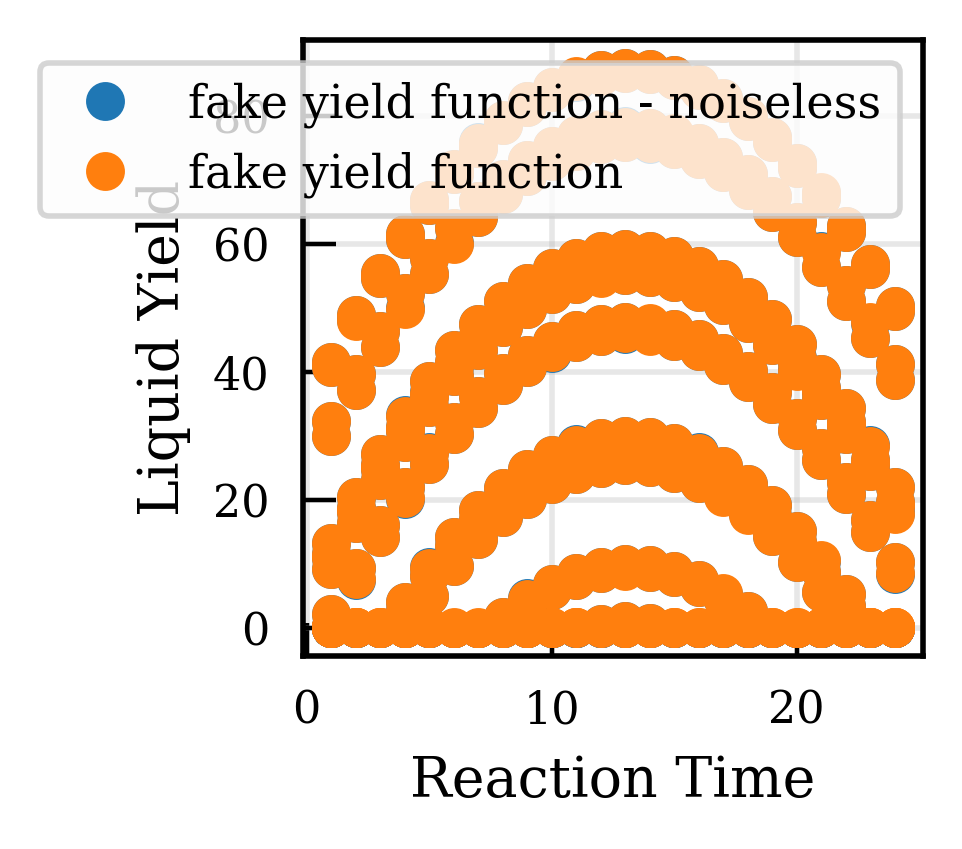

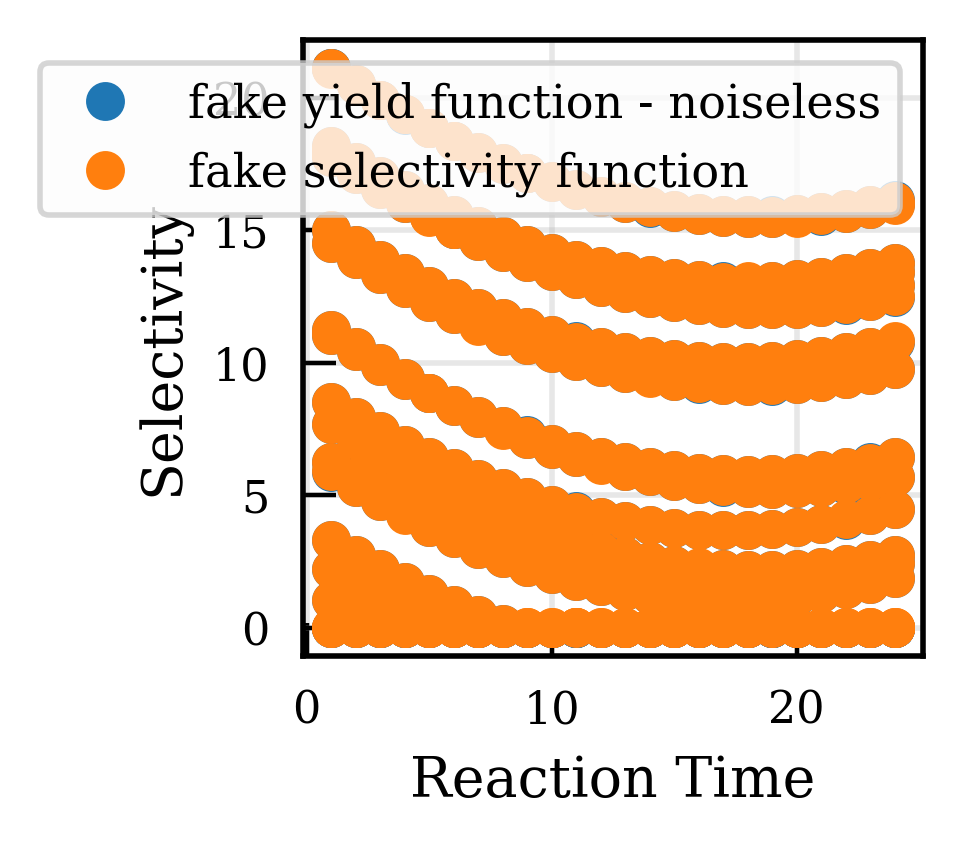

In [ ]:
plt.figure(figsize=(2, 2))
plt.plot(X[:,0], Y_noise_less[:,0],"o",label = 'fake yield function - noiseless')
plt.plot(X[:,0], Y[:,0],"o", label = 'fake yield function')
plt.xlabel('Reaction Time')
plt.ylabel('Liquid Yield')
plt.legend()

plt.show()

plt.figure(figsize=(2, 2))
plt.plot(X[:,0], Y_noise_less[:,1],"o",label = 'fake yield function - noiseless')
plt.plot(X[:,0], Y[:,1], "o", label = 'fake selectivity function')
plt.xlabel('Reaction Time')
plt.ylabel('Selectivity')
plt.legend()
plt.show()

In [ ]:
# Technically we shouldn't be able to normalize since we have collected any data; will fix this up
# Fixed this

x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))


X_norm = x_scaler.fit_transform(X)
# Y_norm = y_scaler.fit_transform(Y) # Ideal Normalization

# Normalization based on parameters
yield_min = 0
yield_max = 100
selectivity_min = 8
selectivity_max = 20

y_scaler.fit(np.array([[yield_min, selectivity_min],[yield_max, selectivity_max]]))
Y_norm = y_scaler.fit_transform(Y)
Y_noise_less_norm = y_scaler.fit_transform(Y_noise_less)
scalers = [x_scaler, y_scaler]

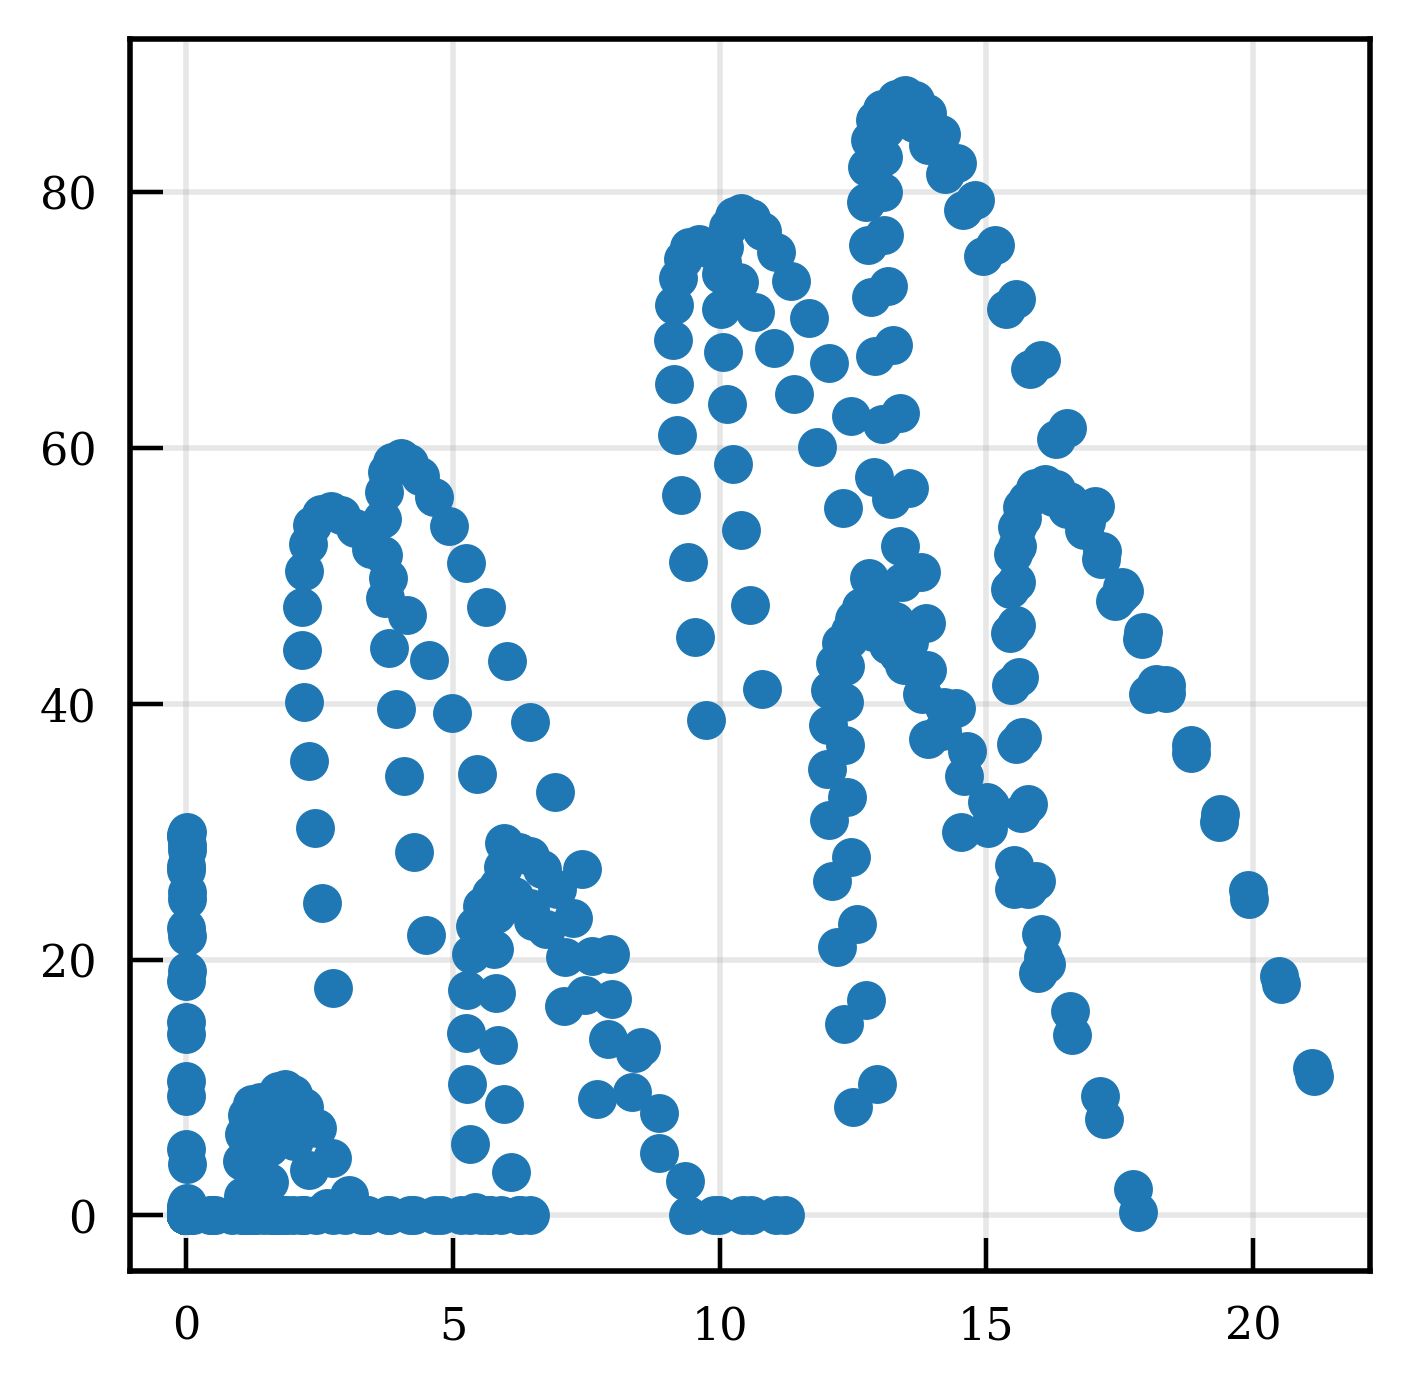

In [ ]:
fig, ax = plt.subplots()
ax.plot(Y[:,1], Y[:,0], "o")
plt.show()

In [ ]:
from src.algorithms import SubsetAlgorithm

class PercentileMaxBinAlgorithm(SubsetAlgorithm):
    def __init__(self, user_algo_params):
        super().__init__(user_algo_params)

    def user_algorithm(self, f_x, x):
        bins_start = self.user_algo_params["bins_start"]
        bins_end = self.user_algo_params["bins_end"]
        bin_epsilon = self.user_algo_params["bin_epsilon"] # Overflow

        target_percentile = self.user_algo_params["target_percentile"] # Target percentile

        list_of_max_ids = []

        f_1 = f_x[:,0] # only take the first property column, yield
        f_2 = f_x[:,1] # only take the first property column, median

        for i in range(0, len(bins_start)):
          ids1 = set(np.where(f_2 >= bins_start[i] - bin_epsilon)[0])
          ids2 = set(np.where(f_2 <= bins_end[i] + bin_epsilon)[0])
          ids3 = list(ids1.intersection(ids2))
          vals = f_1[ids3]
          ids3 = np.array(ids3)
          if len(ids3) != 0:
            value_to_exceed = np.percentile(vals, target_percentile)

            desired_ids = list(np.where(vals >= value_to_exceed)[0])

            list_of_max_ids = list_of_max_ids + list(ids3[desired_ids])



        return list(set(list_of_max_ids))






In [ ]:
from src.algorithms import SubsetAlgorithm

class TopKBinAlgorithm(SubsetAlgorithm):
    def __init__(self, user_algo_params):
        super().__init__(user_algo_params)

    def user_algorithm(self, f_x, x):
        bins_start = self.user_algo_params["bins_start"]
        bins_end = self.user_algo_params["bins_end"]
        bin_epsilon = self.user_algo_params["bin_epsilon"] # Overflow

        topk_num = int(self.user_algo_params["num_points_per_bin"]) # Target topk

        list_of_max_ids = []

        f_1 = f_x[:,0] # only take the first property column, yield
        f_2 = f_x[:,1] # only take the first property column, median

        for i in range(0, len(bins_start)):
          ids1 = set(np.where(f_2 >= bins_start[i] - bin_epsilon)[0])
          ids2 = set(np.where(f_2 <= bins_end[i] + bin_epsilon)[0])
          ids3 = list(ids1.intersection(ids2))
          vals = f_1[ids3]
          ids3 = np.array(ids3)
          if len(ids3) != 0:
            list_of_max_ids = list_of_max_ids + list(ids3[np.flip(np.argsort(vals))[:topk_num]])



        return list(set(list_of_max_ids))






In [ ]:
bins_start = [9, 11, 13, 15, 17]
bins_end = [10, 12, 14, 16, 18]
algorithm=PercentileMaxBinAlgorithm(user_algo_params = {"scalers": scalers,
                                                        "bins_start": bins_start,
                                                        "bins_end": bins_end,
                                                        "target_percentile": 90,
                                                        "bin_epsilon": 0.2 }
                                    )


In [ ]:
bins_start = [9, 11, 13, 15, 17]
bins_end = [10, 12, 14, 16, 18]
algorithm=TopKBinAlgorithm(user_algo_params = {"scalers": scalers,
                                                        "bins_start": bins_start,
                                                        "bins_end": bins_end,
                                                        "num_points_per_bin": 5,
                                                        "bin_epsilon": 0.2 }
                                    )


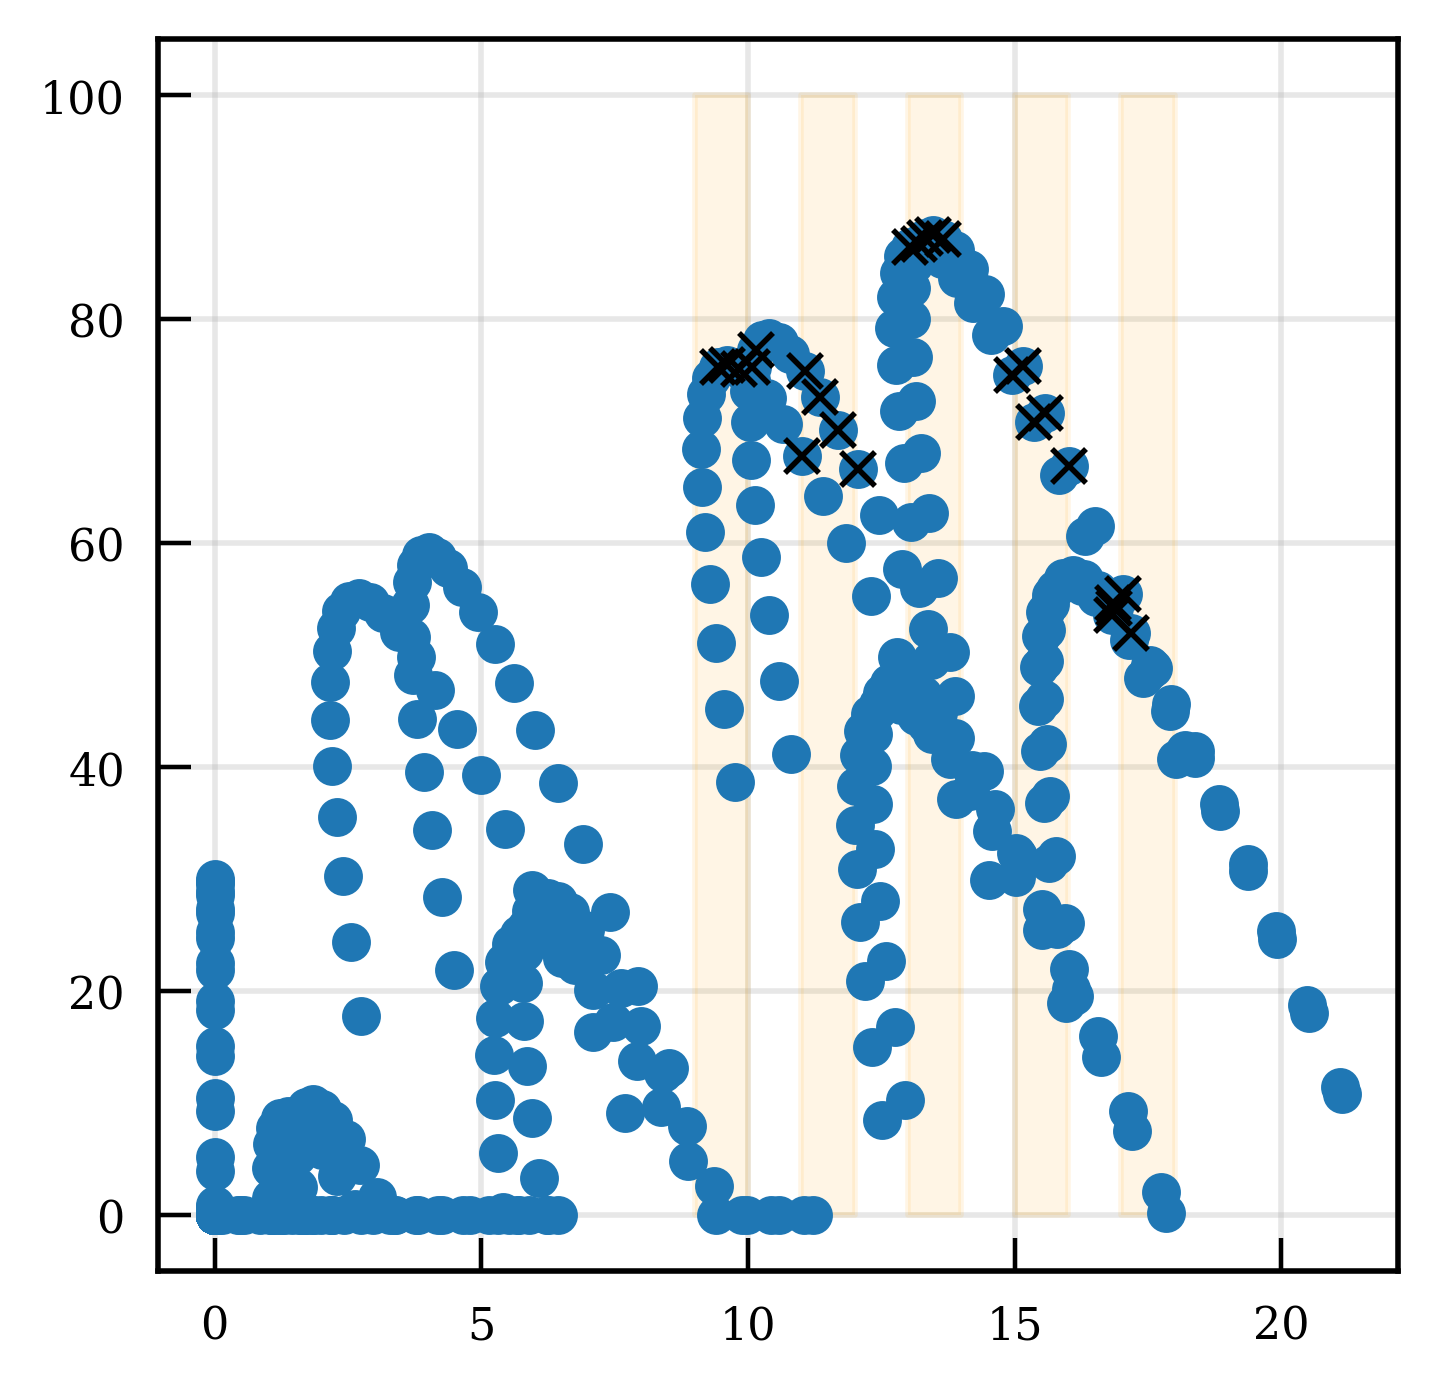

In [ ]:
true_target_ids = algorithm.identify_subspace(f_x=Y_norm, x=X_norm)
fig, ax = plt.subplots()

ax.plot(Y[:,1], Y[:,0], "o")
for i in range(0, len(bins_start)):
  ax.fill_between([bins_start[i],bins_end[i]], 0, 100, alpha=0.1, color="orange")
ax.plot(Y[true_target_ids,1], Y[true_target_ids,0], "kx")


In [ ]:
n_features = 3 # change to 3
n_properties = 2

kernel_initial = ConstantKernel(constant_value=1.0, constant_value_bounds=[0.01, 3.0]) * Matern(nu = 5/2, length_scale= n_features * [1.0], length_scale_bounds= n_features * [[0.01, 3.0]]) + WhiteKernel(noise_level=0.1, noise_level_bounds='fixed')
kernel_initial_list = n_properties * [kernel_initial]
plotting = True
prevent_requery = False # (default this somewhere else)
n_posterior_samples = 5 # relevant for InfoBAX and mixedBAX ~ generally 10-15 is a good number
n_initial = 5# Number of initial datapoints
n_iters = 50 # Number of measurements to be performed
plot_frequency = 50
n_repeats = 1 # Repeats with different dataset initializations
fixed_hypers = True # We should really test this # true uses pre-fixed hypers fit to the entire dataset
adaptive_fit_freq = 2 # Frequency to fit hypers; only applies if fixed_hypers = False


Using strategy: US, repeat number: 0


100%|██████████| 50/50 [00:01<00:00, 25.41it/s]


Using strategy: MeanBAX, repeat number: 0


100%|██████████| 50/50 [00:03<00:00, 16.05it/s]


Using strategy: SwitchBAX, repeat number: 0


100%|██████████| 50/50 [00:04<00:00, 10.71it/s]


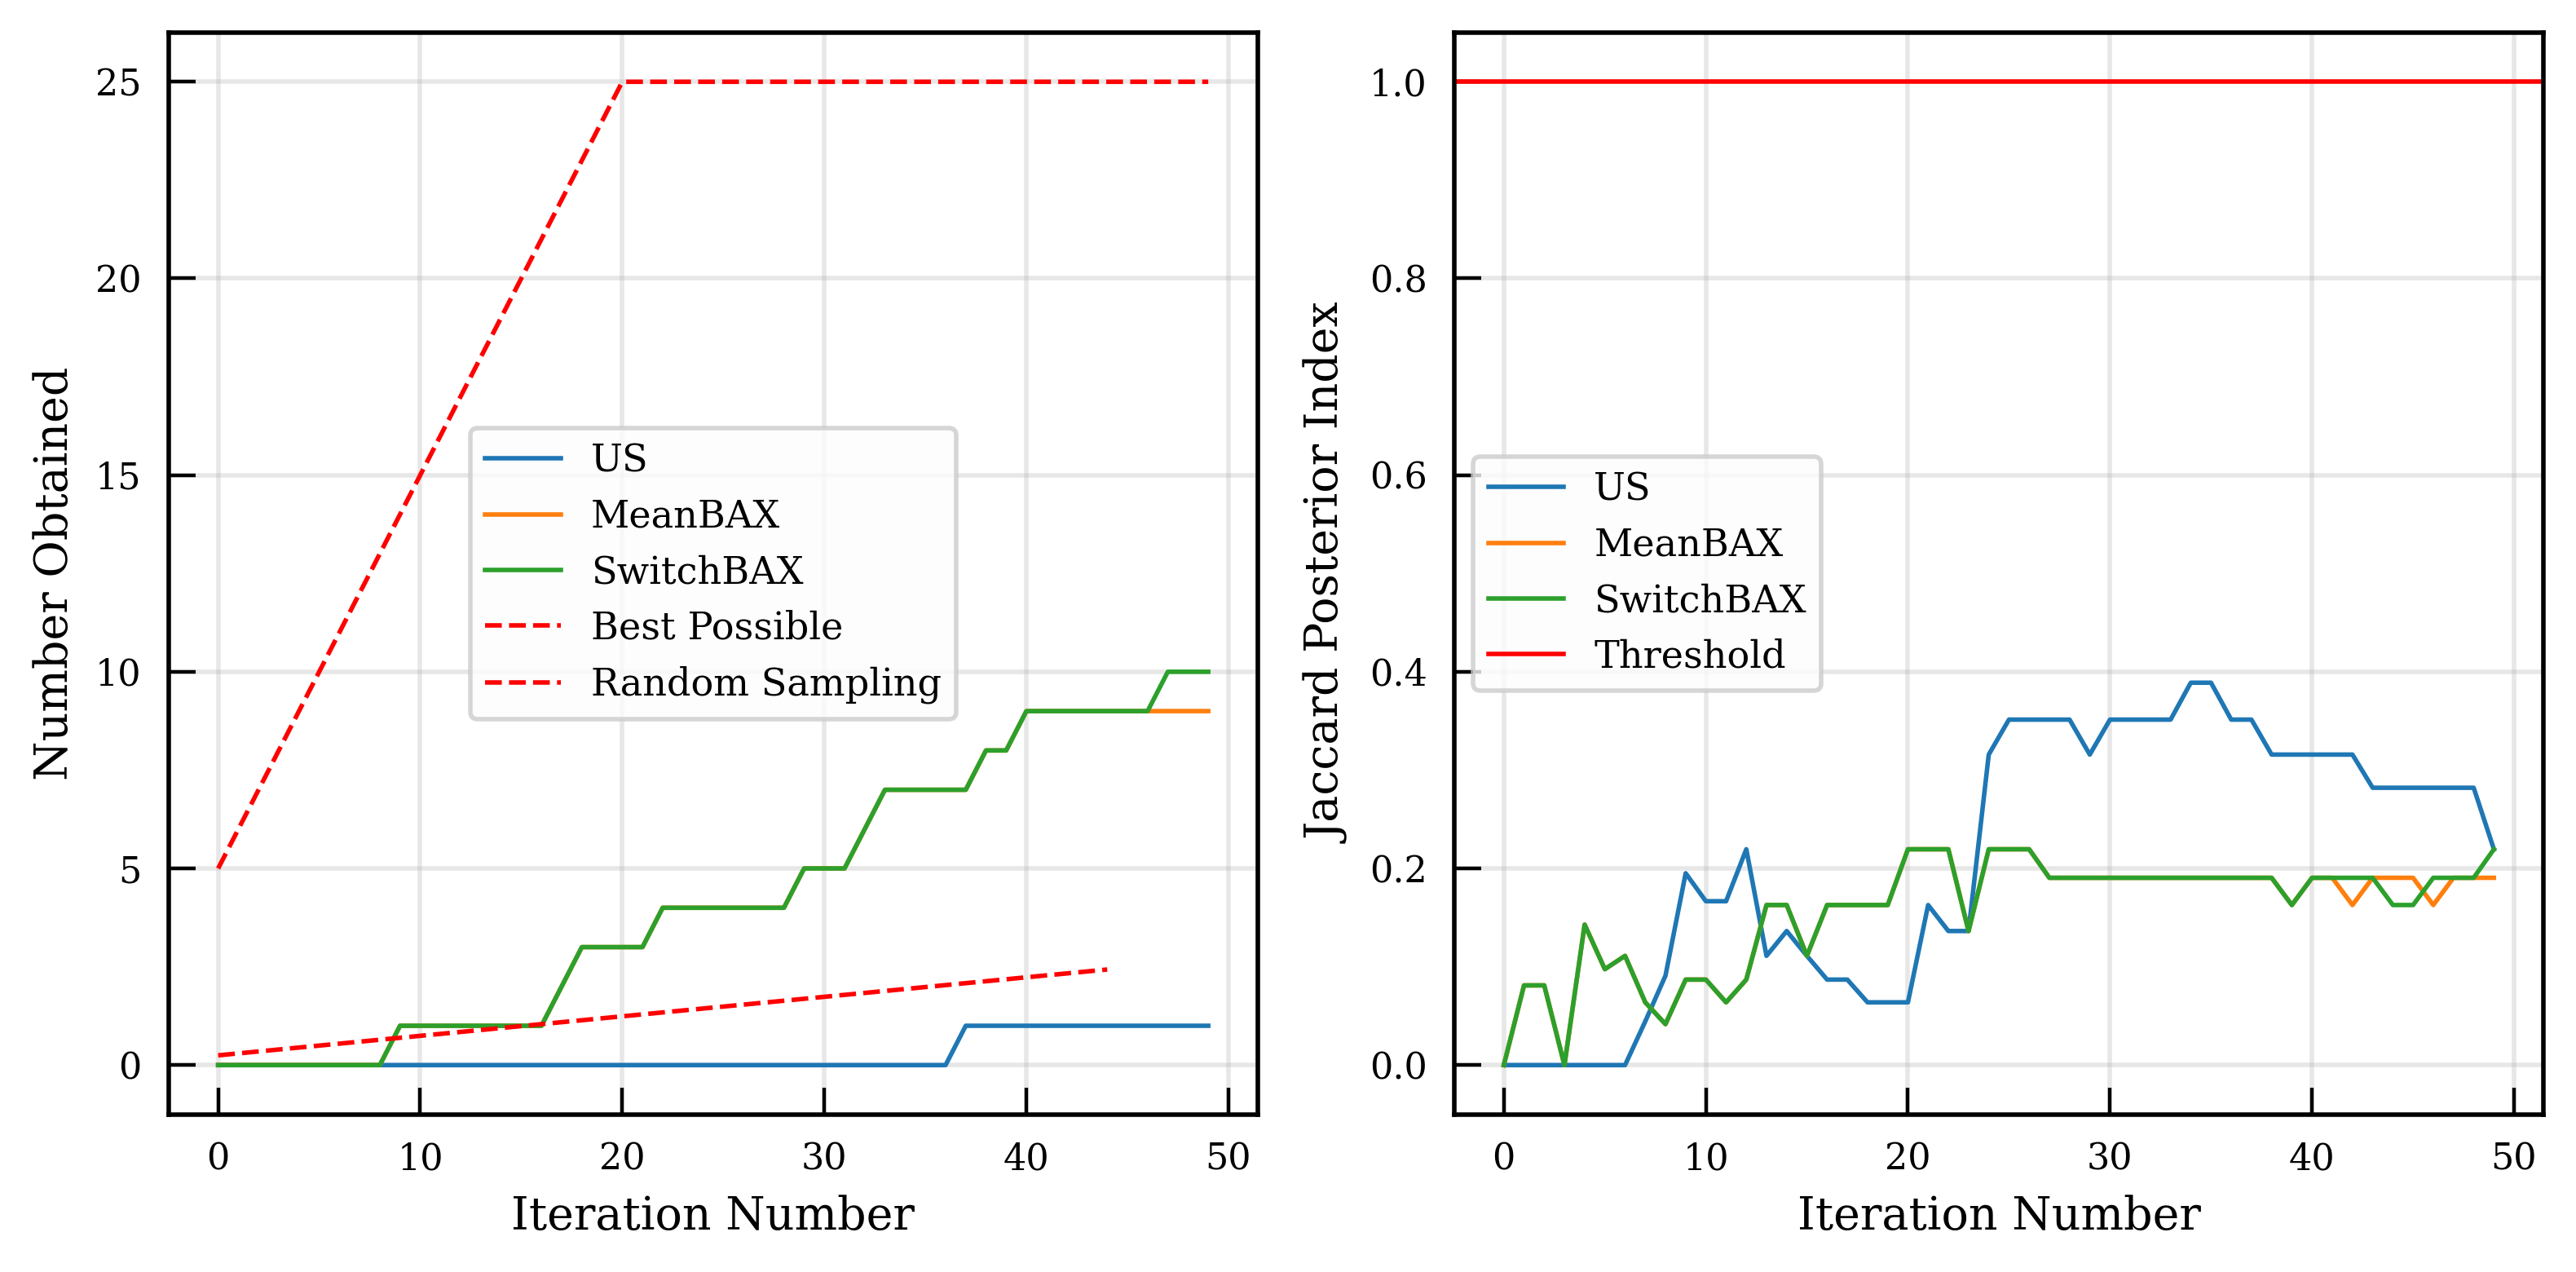

In [ ]:
from logging import StreamHandler
metrics = {
    "SwitchBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "US": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "MeanBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
    "InfoBAX": {"n_obtained": [], "jaccard_posterior_index": [], "switch_strategy": []},
}
all_ids = list(np.arange(0, len(X_norm)))

# Baseling for random sampling without replacement (expectation of hypergeometric distribution)
random_sampling = [random_sampling_no_replace(len(X_norm), len(true_target_ids), n) for n in range(n_initial, n_iters)]

# Baseline for best possible acquisition (i.e. acquire a target point at each iteration; need an "oracle" to do this)
if n_iters <= len(true_target_ids):
    best_possible_n_obtained = np.arange(n_initial, n_iters + n_initial)
else:
    best_possible_n_obtained = list(np.arange(n_initial, len(true_target_ids))) + list(
        len(true_target_ids) * np.ones(n_iters + n_initial - len(true_target_ids))
    )

# Acquisition functions that use BAX for subset estimation
strategies = ["US", "MeanBAX", "SwitchBAX"]

collected_collection = {}
for strat in strategies:
  collected_collection.update({strat: None})
# Calculate hypers based on the entire dataset; this is not possible in a real experiment but allows us to compare acquisition fn to acquisition fn
if fixed_hypers:
  kernel_list = fit_matern_hypers(x_train=X_norm, y_train=Y_norm, kernel_list=kernel_initial_list, n_restarts_optimizer=1)

for strategy in strategies:
    for j in range(n_repeats):  # to see variance w.r.t initial datapoint choice

        print("Using strategy: {}, repeat number: {}".format(strategy, j))

        np.random.seed(j) # make sure all strategies get same initial points
        train_indices = list(np.random.choice(all_ids, n_initial))
        x_train = X_norm[train_indices]
        y_train = Y_norm[train_indices]

        collected_ids = list(train_indices)
        n_obtained_list = []
        jaccard_posterior_list = []
        switch_list = []

        for i in tqdm(range(n_iters)):
            # Adaptive hyperparameter fitting
            if (i % adaptive_fit_freq == 0) and (fixed_hypers == False):
                kernel_list = fit_matern_hypers(x_train=x_train, y_train=y_train, kernel_list=kernel_initial_list)

            # Define GP model with fixed, fitted hypers. Note, we need this so that all the n_posterior models for InfoBAX have the same kernel
            multi_gpr = MGPR(kernel_list=kernel_list)

            # Acquire next index
            x_train, y_train, model, collected_ids, acquisition_function, switch_strategy = run_acquisition(
                x_train, y_train, X_norm, Y_norm, strategy, algorithm, multi_gpr, collected_ids, n_posterior_samples
            )

            # Calculate metrics
            posterior_mean, posterior_std = model.predict(X_norm)


            predicted_target_ids = algorithm.identify_subspace(f_x = posterior_mean, x=X_norm)
            n_obtained_list.append(get_n_obtained(collected_ids, true_target_ids))
            jaccard_posterior_list.append(get_jaccard_posterior(predicted_target_ids, true_target_ids))
            switch_list.append(switch_strategy)

            if (i % plot_frequency == 0) and (plotting) and (i != 0):

                for k in range(2):
                  plt.plot(X_norm, posterior_mean[:,k], color = 'blue')
                  plt.plot(X_norm, Y_norm[:, k], color = 'red')
                  plt.fill_between(X_norm[:,0], posterior_mean[:,k] - 1.96 * posterior_std[:,k], y2=posterior_mean[:,k] + 1.96 * posterior_std[:,k], alpha = 0.1)
                  plt.scatter(x_train, y_train[:,k], color = 'k')

                  for i in true_target_ids:
                    plt.axvline(x = X_norm[i], color = 'green')
                  plt.show()


                plot_iteration_results(
                    np.hstack((X_norm, X_norm)),
                    Y_norm,
                    x_scaler,
                    y_scaler,
                    collected_ids,
                    true_target_ids,
                    predicted_target_ids,
                    acquisition_function,
                    n_obtained_list,
                    jaccard_posterior_list,
                    best_possible_n_obtained,
                    random_sampling,
                    n_initial
                )

        metrics[strategy]["n_obtained"].append(n_obtained_list)
        metrics[strategy]["jaccard_posterior_index"].append(jaccard_posterior_list)
        metrics[strategy]["switch_strategy"].append(switch_list)

    collected_collection.update({strat: collected_ids})
plot_final_metrics(n_iters, metrics, strategies, best_possible_n_obtained, random_sampling)


[172, 47, 117, 192, 323, 95, 167, 274, 409, 102, 1, 247, 34, 132, 302, 33, 99, 280, 137, 32, 283, 112, 31, 303, 299, 133, 103, 35, 260, 30, 111, 300, 136, 104, 275, 301, 135, 252, 105, 134, 101, 278, 106, 276, 305, 277, 69, 259, 38, 39, 29, 304, 37, 503, 264]


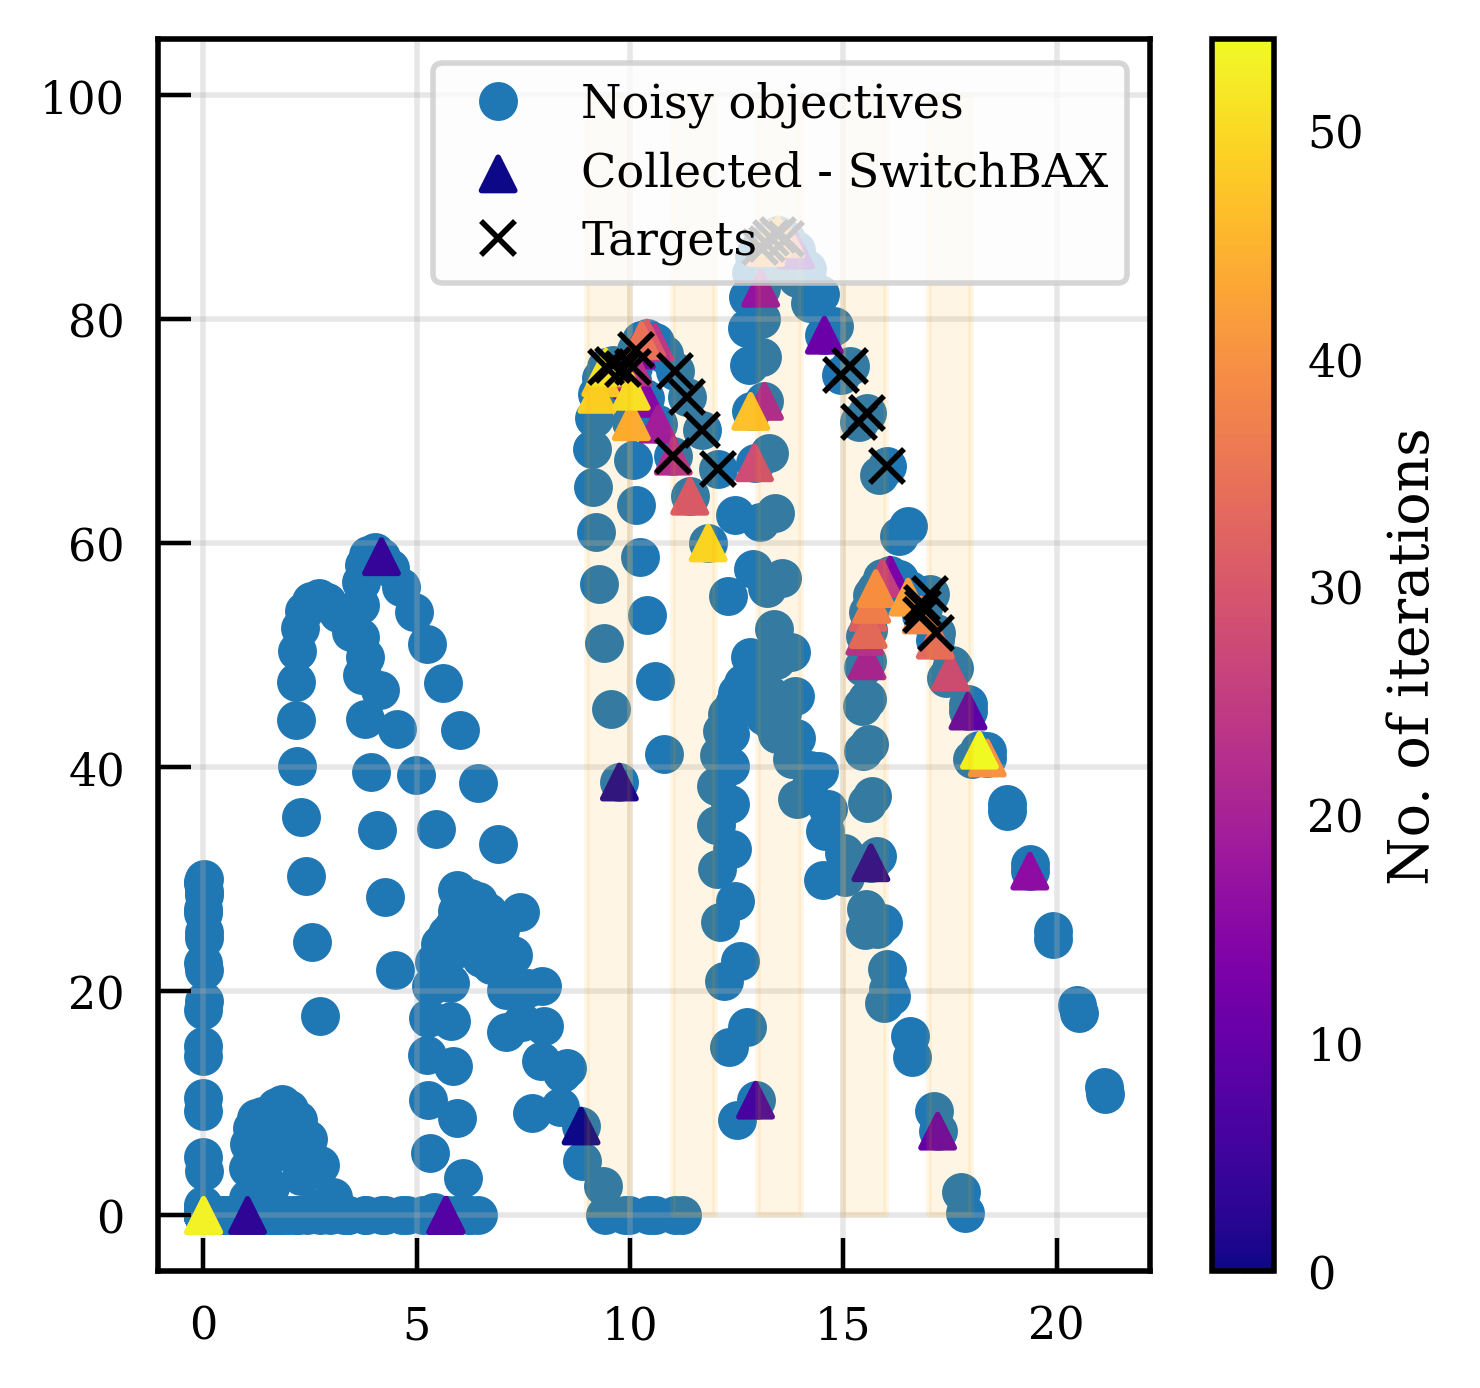

In [ ]:
true_target_ids = algorithm.identify_subspace(f_x=Y_norm, x=X_norm)

fig, ax = plt.subplots()
print(collected_ids)
ax.plot(Y[:,1], Y[:,0], "o", zorder=0, label="Noisy objectives")

sm = ax.scatter(Y[collected_ids, 1], Y[collected_ids, 0], marker="^", c=np.arange(len(collected_ids)),cmap="plasma", zorder=1, label="Collected - SwitchBAX")
for i in range(0, len(bins_start)):
  ax.fill_between([bins_start[i],bins_end[i]], 0, 100, alpha=0.1, color="orange")
ax.plot(Y[true_target_ids,1], Y[true_target_ids,0], "kx", label="Targets")
cb = fig.colorbar(sm)
cb.set_label("No. of iterations")
ax.legend()
plt.show()
